# Dummy PMT single photoelectron (SPE) pulse shape

When a photoelectron is amplified by the PMT, the anode delivers a short current pulse. The ember plugin `PMTResponseAndDAQ` (like fuse) builds every waveform as a sum of such pulses: one per photon, scaled with the photon's gain and placed at the photon's arrival time. It needs the **shape** of one pulse; its area is set by the gain.

This notebook writes a **dummy pulse shape** based on public measurements of the Hamamatsu R11410-10 (Lung et al. 2012, [arXiv:1202.2628](https://arxiv.org/abs/1202.2628), section 4.3), measured at -1750 V with a 2 GHz oscilloscope:

| Quantity | Value |
|---|---|
| Rise time (10 % → 90 %) | 2.6 ± 0.4 ns |
| Fall time (90 % → 10 %) | 9.7 ± 0.5 ns |
| Pulse width (FWHM) | 7.2 ± 0.6 ns |

The pulse is modelled as a log-normal function of time (`ember.pmt_pulse_model.lognormal_pulse_shape`). Its two parameters are fitted to reproduce the three values above.

These values describe the bare PMT pulse. In a real detector the cables, the amplifier and the limited bandwidth of the digitizer widen the pulse that the DAQ records. We model this by smearing the pulse with a normal distribution with the standard deviation `pmt_pulse_smearing_sigma` from `ember/config/detector.yaml` (default 3 ns: the FWHM grows from 7.2 ns to about 10.5 ns). To change it, edit `detector.yaml` and run this notebook again. Then bump the version of `PMTResponseAndDAQ` or delete the cached `raw_records` (see the lineage caveat in `CLAUDE.md`).

**Limitation:** a real readout chain can also add a long tail or reflections, which the smearing does not describe. Replace the file with a pulse shape measured with your own readout chain (e.g. the average of many SPE waveforms) if you have one.

### Format

A JSON file with fuse's two keys:

| Key | Content |
|---|---|
| `pe_pulse_ts` | Times of the pulse samples relative to the photon arrival time [ns], on a 1 ns grid. |
| `pe_pulse_ys` | Pulse amplitude at these times (any normalization; the plugin normalizes the area to 1 PE). |

Before the smearing the maximum of the pulse is at `t = 0`, as in fuse. The smearing keeps the mean time of the pulse and moves the maximum by about 1 ns. The transit time of the PMT is added to the photon times earlier, in the photon propagation plugins.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

import strax

import ember
from ember.pmt_pulse_model import (
    fit_lognormal_pulse,
    lognormal_pulse_shape,
    measure_pulse_timing,
    smear_pulse_shape,
)
from ember.url_protocols import DUMMY_MAP_DIRECTORY

## Fit the log-normal pulse to the measured timing

In [2]:
rise_time = 2.6  # ns, 10 % -> 90 %
fall_time = 9.7  # ns, 90 % -> 10 %
fwhm = 7.2  # ns

scale, sigma = fit_lognormal_pulse(rise_time, fall_time, fwhm)
print(f"scale = {scale:.4f} ns, sigma = {sigma:.4f}")

fine_times = np.arange(-20, 100, 0.01)
fitted_timing = measure_pulse_timing(fine_times, lognormal_pulse_shape(fine_times, scale, sigma))
print("Fitted rise time, fall time, FWHM [ns]:", np.round(fitted_timing, 2))

scale = 5.7013 ns, sigma = 0.5061
Fitted rise time, fall time, FWHM [ns]: [2.59 9.7  7.2 ]


## Smearing by the readout chain

The smearing is done on a fine grid (0.1 ns). The grid starts well before the pulse, so no area is lost at the edges.

In [3]:
smearing_sigma = strax.URLConfig.evaluate_dry("detector://pmt_pulse_smearing_sigma")  # ns

fine_grid = np.arange(-60, 260, 0.1)  # ns
bare_pulse = lognormal_pulse_shape(fine_grid, scale, sigma)
smeared_pulse = smear_pulse_shape(fine_grid, bare_pulse, smearing_sigma)

print("Smearing sigma:", smearing_sigma, "ns")
print("Bare pulse:    rise, fall, FWHM [ns] =", np.round(measure_pulse_timing(fine_grid, bare_pulse), 2))
print("Smeared pulse: rise, fall, FWHM [ns] =", np.round(measure_pulse_timing(fine_grid, smeared_pulse), 2))

Smearing sigma: 3.0 ns
Bare pulse:    rise, fall, FWHM [ns] = [2.6 9.7 7.2]
Smeared pulse: rise, fall, FWHM [ns] = [ 6.34 10.58 10.54]


## Pulse on the 1 ns grid

The plugin needs the pulse between `-samples_before_pulse_center` and `+samples_after_pulse_center` samples (-20 ns to +200 ns with 10 ns samples). We take the smeared pulse at every full ns of this range and normalize the area to 1.

Area within the first 30 ns: 0.9988118208080933


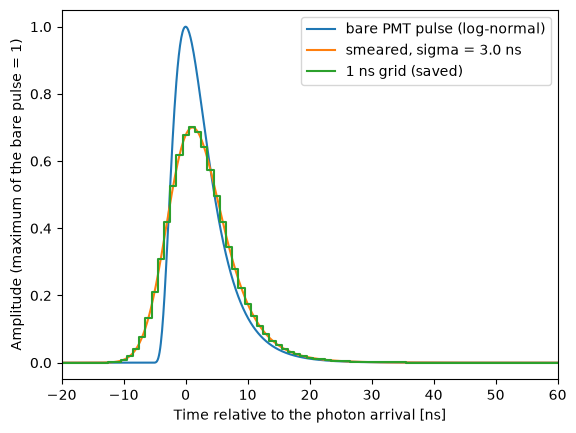

In [4]:
pulse_times = np.arange(-20, 201, 1)  # ns
pulse_amplitudes = np.interp(pulse_times, fine_grid, smeared_pulse)
pulse_amplitudes /= pulse_amplitudes.sum()

print("Area within the first 30 ns:", pulse_amplitudes[pulse_times < 30].sum())

plt.plot(fine_grid, bare_pulse / bare_pulse.max(), label="bare PMT pulse (log-normal)")
plt.plot(fine_grid, smeared_pulse / bare_pulse.max(), label=f"smeared, sigma = {smearing_sigma} ns")
plt.step(pulse_times, pulse_amplitudes / pulse_amplitudes.max() * smeared_pulse.max() / bare_pulse.max(), where="mid", label="1 ns grid (saved)")
plt.xlim(-20, 60)
plt.xlabel("Time relative to the photon arrival [ns]")
plt.ylabel("Amplitude (maximum of the bare pulse = 1)")
plt.legend()
plt.show()

With 10 ns samples, most of the pulse falls into one or two samples. The plot shows how much of the area each 10 ns sample receives for a photon arriving at the start of a sample.

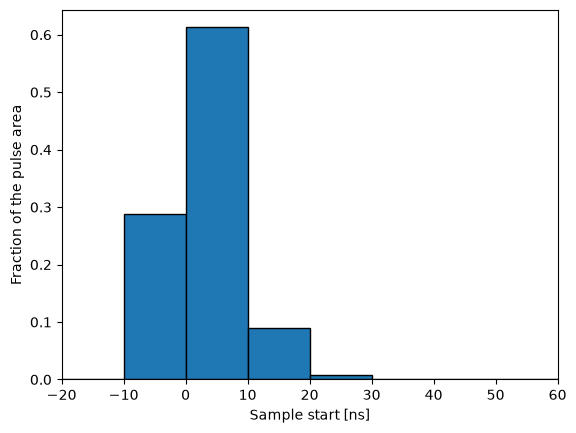

In [5]:
sample_edges = np.arange(-20, 201, 10)
area_per_sample, _ = np.histogram(pulse_times, bins=sample_edges, weights=pulse_amplitudes)

plt.bar(sample_edges[:-1], area_per_sample, width=10, align="edge", edgecolor="black")
plt.xlim(-20, 60)
plt.xlabel("Sample start [ns]")
plt.ylabel("Fraction of the pulse area")
plt.show()

In [6]:
pulse_shape = {
    "pe_pulse_ts": pulse_times.tolist(),
    "pe_pulse_ys": [float(f"{amplitude:.6g}") for amplitude in pulse_amplitudes],
}
output_file = DUMMY_MAP_DIRECTORY / "pmt_pulse_shape_dummy.json"
with open(output_file, "w") as json_file:
    json.dump(pulse_shape, json_file)
print("Saved", output_file)

Saved /mnt/d/XLZD/mymodules/ember/ember/dummy_maps/pmt_pulse_shape_dummy.json
